In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set display options for clear viewing of all columns and rows
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Configure visualization styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Load the dataset
df = pd.read_csv('Dataset.csv')

# Display basic dataset information
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns")
print("\n--- First 3 Rows of the Dataset ---")
display(df.head(3))

Dataset Shape: 7043 rows and 50 columns

--- First 3 Rows of the Dataset ---


,CustomerID,Gender,Age,Under30,SeniorCitizen,Married,Dependents,NumberofDependents,Country,State,City,ZipCode,Latitude,Longitude,Population,Quarter,ReferredaFriend,Number_of_Referrals,TenureinMonths,Offer,PhoneService,AvgMonthlyLongDistanceCharges,MultipleLines,InternetService,InternetType,AvgMonthlyGBDownload,OnlineSecurity,OnlineBackup,DeviceProtectionPlan,PremiumTechSupport,StreamingTV,StreamingMovies,StreamingMusic,UnlimitedData,Contract,PaperlessBilling,PaymentMethod,MonthlyCharge,TotalCharges,TotalRefunds,TotalExtraDataCharges,TotalLongDistanceCharges,TotalRevenue,SatisfactionScore,CustomerStatus,ChurnLabel,ChurnScore,CLTV,ChurnCategory,ChurnReason
0,8779-QRDMV,Male,78,No,Yes,No,No,0,United States,California,Los Angeles,90022,34.023810,-118.156582,68701,Q3,No,0,1,NaN,No,0.00,No,Yes,DSL,8,No,No,Yes,No,No,Yes,No,No,Month-to-Month,Yes,Bank Withdrawal,39.65,39.65,0.00,20,0.00,59.65,3,Churned,Yes,91,5433,Competitor,Competitor offered more data
1,7495-OOKFY,Female,74,No,Yes,Yes,Yes,1,United States,California,Los Angeles,90063,34.044271,-118.185237,55668,Q3,Yes,1,8,Offer E,Yes,48.85,Yes,Yes,Fiber Optic,17,No,Yes,No,No,No,No,No,Yes,Month-to-Month,Yes,Credit Card,80.65,633.30,0.00,0,390.80,1024.10,3,Churned,Yes,69,5302,Competitor,Competitor made better offer
2,1658-BYGOY,Male,71,No,Yes,No,Yes,3,United States,California,Los Angeles,90065,34.108833,-118.229715,47534,Q3,No,0,18,Offer D,Yes,11.33,Yes,Yes,Fiber Optic,52,No,No,No,No,Yes,Yes,Yes,Yes,Month-to-Month,Yes,Bank Withdrawal,95.45,1752.55,45.61,0,203.94,1910.88,2,Churned,Yes,81,3179,Competitor,Competitor made better offer


In [2]:
# Inspect data types and non-null counts
print("--- Dataset Information ---")
print(df.info())

# Check for missing values in each column
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_values, 'Missing Percentage (%)': missing_percentage})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print("\n--- Columns with Missing Values ---")
display(missing_df)

# Check basic statistical summary for numerical columns
print("\n--- Numerical Summary ---")
display(df.describe().T[['count', 'mean', 'std', 'min', 'max']])

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 50 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   CustomerID                     7043 non-null   object 
 1   Gender                         7043 non-null   object 
 2   Age                            7043 non-null   int64  
 3   Under30                        7043 non-null   object 
 4   SeniorCitizen                  7043 non-null   object 
 5   Married                        7043 non-null   object 
 6   Dependents                     7043 non-null   object 
 7   NumberofDependents             7043 non-null   int64  
 8   Country                        7043 non-null   object 
 9   State                          7043 non-null   object 
 10  City                           7043 non-null   object 
 11  ZipCode                        7043 non-null   int64  
 12  Latitude            

,Missing Count,Missing Percentage (%)
ChurnCategory,5174,73.463013
ChurnReason,5174,73.463013
Offer,3877,55.047565
InternetType,1526,21.666903



--- Numerical Summary ---


,count,mean,std,min,max
Age,7043.0,46.509726,16.750352,19.000000,80.000000
NumberofDependents,7043.0,0.468692,0.962802,0.000000,9.000000
ZipCode,7043.0,93486.070567,1856.767505,90001.000000,96150.000000
Latitude,7043.0,36.197455,2.468929,32.555828,41.962127
Longitude,7043.0,-119.756684,2.154425,-124.301372,-114.192901
Population,7043.0,22139.603294,21152.392837,11.000000,105285.000000
Number_of_Referrals,7043.0,1.951867,3.001199,0.000000,11.000000
TenureinMonths,7043.0,32.386767,24.542061,1.000000,72.000000
AvgMonthlyLongDistanceCharges,7043.0,22.958954,15.448113,0.000000,49.990000
AvgMonthlyGBDownload,7043.0,20.515405,20.418940,0.000000,85.000000


In [3]:
# Filter out 'Joined' customers to focus strictly on Stayed and Churned cohorts for churn modeling
df_filtered = df[df['CustomerStatus'] != 'Joined'].copy()

print(f"Original shape: {df.shape}")
print(f"Shape after filtering out 'Joined' customers: {df_filtered.shape}")

# Handle missing values for categorical features where NaN means 'None' or 'No Offer'
df_filtered['Offer'] = df_filtered['Offer'].fillna('None')
df_filtered['InternetType'] = df_filtered['InternetType'].fillna('None')

# For ChurnCategory and ChurnReason, NaN represents customers who stayed (no churn event occurred)
df_filtered['ChurnCategory'] = df_filtered['ChurnCategory'].fillna('Not Applicable')
df_filtered['ChurnReason'] = df_filtered['ChurnReason'].fillna('Not Applicable')

# Verify that no missing values remain
print("\n--- Missing Values After Treatment ---")
print(df_filtered[['Offer', 'InternetType', 'ChurnCategory', 'ChurnReason']].isnull().sum())

Original shape: (7043, 50)
Shape after filtering out 'Joined' customers: (6589, 50)

--- Missing Values After Treatment ---
Offer            0
InternetType     0
ChurnCategory    0
ChurnReason      0
dtype: int64


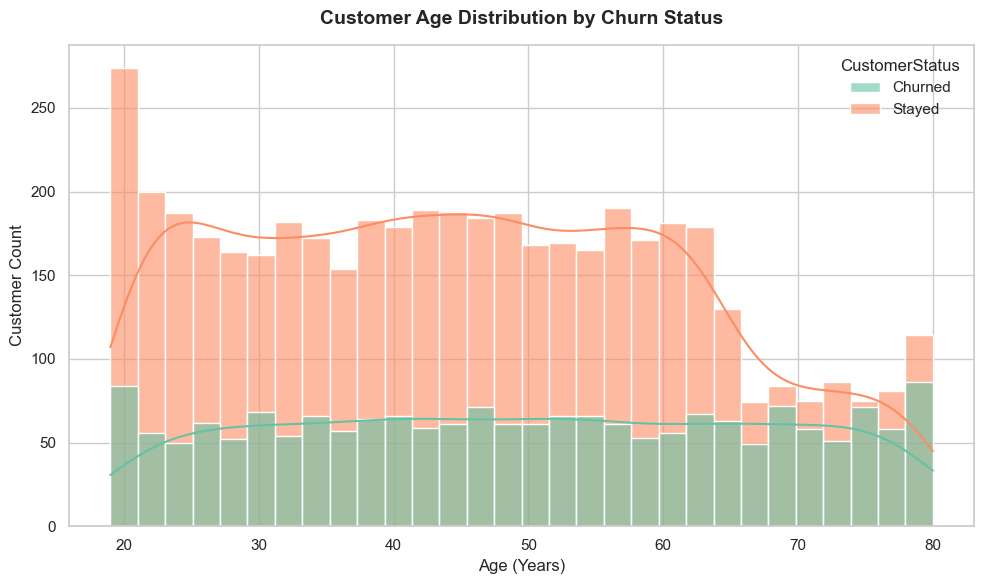

<Figure size 900x500 with 0 Axes>

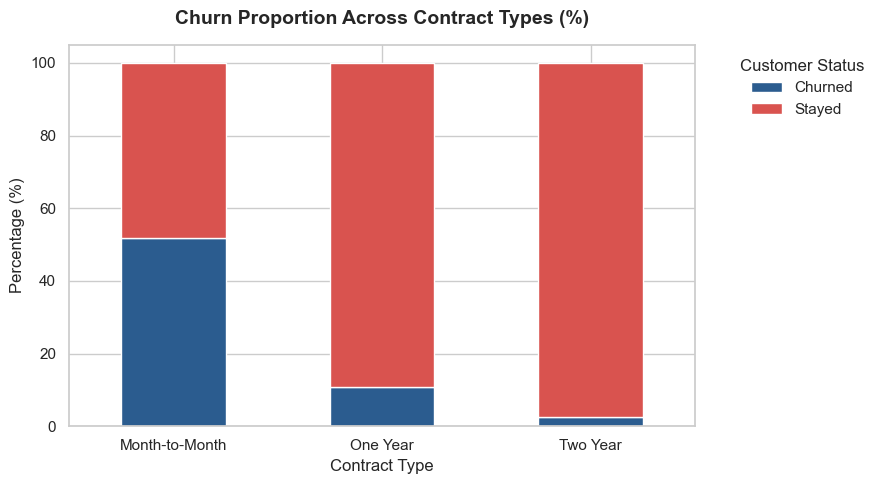

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

# ---Customer Age Distribution by Churn Status ---
plt.figure(figsize=(10, 6))
sns.histplot(data=df_filtered, x='Age', hue='CustomerStatus', kde=True, bins=30, palette='Set2', alpha=0.6)
plt.title('Customer Age Distribution by Churn Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Customer Count', fontsize=12)
plt.show()

# ---Churn Proportion Across Contract Types ---
plt.figure(figsize=(9, 5))
contract_churn = pd.crosstab(df_filtered['Contract'], df_filtered['CustomerStatus'], normalize='index') * 100
contract_churn.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d9534f'], figsize=(9, 5))
plt.title('Churn Proportion Across Contract Types (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Contract Type', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.legend(title='Customer Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.show()

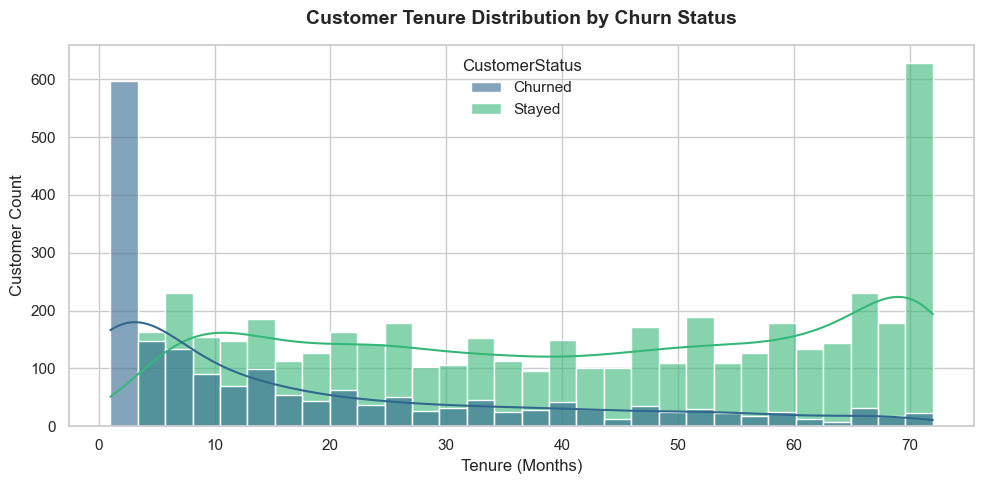

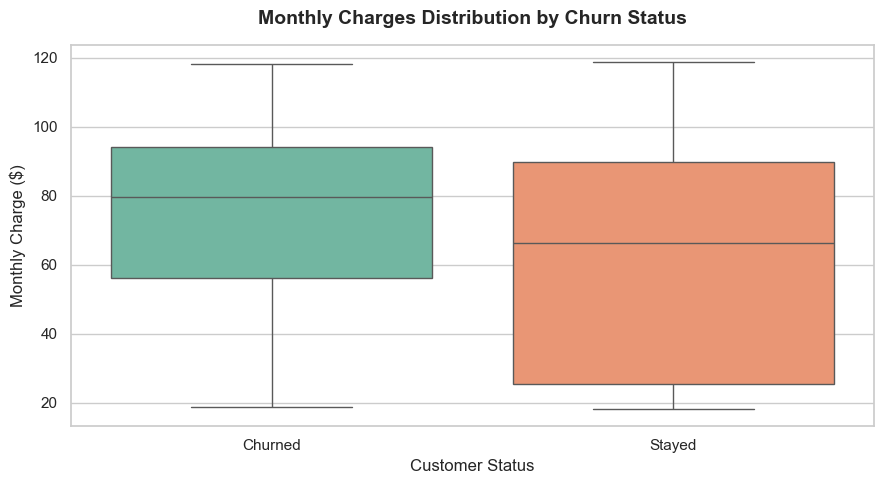

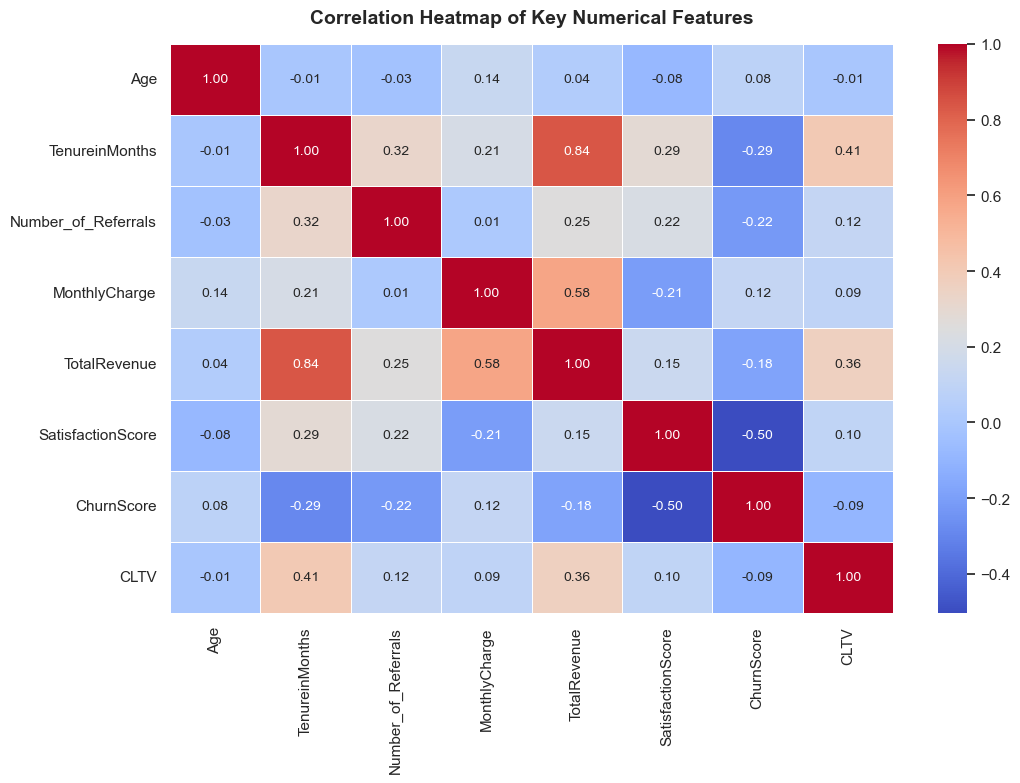

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

# ---Tenure in Months vs Churn Status ---
plt.figure(figsize=(10, 5))
sns.histplot(data=df_filtered, x='TenureinMonths', hue='CustomerStatus', kde=True, bins=30, palette='viridis', alpha=0.6)
plt.title('Customer Tenure Distribution by Churn Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tenure (Months)', fontsize=12)
plt.ylabel('Customer Count', fontsize=12)
plt.show()

# ---Monthly Charges vs Churn Status (Warning Resolved) ---
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_filtered, x='CustomerStatus', y='MonthlyCharge', hue='CustomerStatus', palette='Set2', legend=False)
plt.title('Monthly Charges Distribution by Churn Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Customer Status', fontsize=12)
plt.ylabel('Monthly Charge ($)', fontsize=12)
plt.show()

# ---Correlation Heatmap for Key Numerical Features ---
plt.figure(figsize=(11, 8))
num_cols = ['Age', 'TenureinMonths', 'Number_of_Referrals', 'MonthlyCharge', 'TotalRevenue', 'SatisfactionScore', 'ChurnScore', 'CLTV']
corr_matrix = df_filtered[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True, annot_kws={"size": 10})
plt.title('Correlation Heatmap of Key Numerical Features', fontsize=14, fontweight='bold', pad=15)
plt.show()

In [6]:
# Save the cleaned dataset
df_filtered.to_csv('cleaned_dataset.csv', index=False)
print("Cleaned dataset successfully saved as 'cleaned_dataset.csv'!")

Cleaned dataset successfully saved as 'cleaned_dataset.csv'!
